# Kernel EM with a PET prior: Lu-177 SPECT guided by Ga-68 PET

In theranostics the same molecule is often imaged twice: with Ga-68 on PET before treatment, and with Lu-177 on SPECT
after it. The PET image is sharper and less noisy, and it shows where the molecule goes. Kernel expectation
maximization (KEM) uses it as a prior. The SPECT image is written as $f = K\alpha$: each row of the kernel matrix $K$
averages a voxel's coefficient with those of the $k$ neighbours that look most like it in the PET image, and EM
reconstructs the coefficients $\alpha$ through the system matrix $HK$. The kernel is fixed during the reconstruction.

This tutorial builds the kernel in two ways and compares both with MLEM on a simulated Lu-177 DOTATATE scan of the
Zubal phantom:

- From the PET image's intensities, with Gaussian weights in intensity and in distance (`construct_kernel`).
- From features that a 3D U-Net learns from the PET image: the deep-learned kernel of Wei, Livieratos and Reader
  (`train_deep_kernel` and `construct_deep_kernel`).

Any prior image on the reconstruction's grid works the same way, for example an MR image for PET.

The kernel methods and the data were contributed by H. Wei. If you use them, please cite H. Wei, L. Livieratos and
A. J. Reader, "PET-informed deep-learned kernel method for theranostic SPECT reconstruction", *IEEE Transactions on
Radiation and Plasma Medical Sciences* (2026), [doi:10.1109/TRPMS.2026.3737413](https://doi.org/10.1109/TRPMS.2026.3737413).

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("SPECT/Lu177-DOTATATE-Zubal")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("SPECT/Lu177-DOTATATE-Zubal")

SPECT/Lu177-DOTATATE-Zubal: already downloaded


In [2]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
import pytomography
from pytomography.metadata.SPECT import SPECTObjectMeta, SPECTProjMeta, SPECTPSFMeta
from pytomography.transforms.SPECT import SPECTAttenuationTransform, SPECTPSFTransform
from pytomography.transforms.shared import ExternalKEMTransform
from pytomography.transforms.shared.external_kem import (UNet3D, construct_deep_kernel, construct_kernel,
                                                         train_deep_kernel)
from pytomography.projectors.SPECT import SPECTSystemMatrix
from pytomography.projectors.shared import KEMSystemMatrix
from pytomography.likelihoods import PoissonLogLikelihood
from pytomography.algorithms import KEM, OSEM

In [3]:
# Memory: a kernel holds k = 50 neighbours for each of the 128^3 voxels (float32 weights and int64 indices, 1.3 GB). It
# stays in RAM and goes to the GPU a chunk at a time; the tutorial peaks at about 9 GB of RAM (measured on Windows).
# Training the U-Net takes about 1.4 GB of GPU memory with chunk_size=8192 below: halve chunk_size to halve it.
# Nothing here grows with RAM_GB.
RAM_GB = 25
pytomography.set_memory_budget(RAM_GB)

## 1. The data

The data are NumPy arrays in PyTomography's [conventions](../conventions.md): a grid of 128 × 128 × 128 voxels of
4 mm, with its axes to the patient's left (x), back (y) and head (z).

- A simulated Ga-68 DOTATATE PET image, the prior.
- The attenuation map at Lu-177's 208 keV photopeak, in 1/mm.
- Lu-177 DOTATATE SPECT projections (views, r, z): 120 views over 360° at a radius of 300 mm, 128 × 128 bins of 4 mm,
  20 million counts. They were simulated with the attenuation map and a Gaussian collimator blur of width
  $\sigma = 0.02\,d + 1.0$ mm at distance $d$ from the collimator, and the system matrix below uses the same model.

For a real scan the metadata come from its files: see the [DICOM](t_dicomdata.ipynb) and
[SIMIND](t_siminddata.ipynb) introductions.

In [4]:
path = DATA / 'SPECT' / 'Lu177-DOTATATE-Zubal'
pet_prior = np.load(path / 'pet_prior.npy')
attenuation_map = torch.as_tensor(np.load(path / 'attenuation_map.npy'), device=pytomography.device)
projections = torch.as_tensor(np.load(path / 'projections.npy'), device=pytomography.device)

object_meta = SPECTObjectMeta(dr=(4.0, 4.0, 4.0), shape=(128, 128, 128))
proj_meta = SPECTProjMeta(projection_shape=(128, 128), dr=(4.0, 4.0),
                          angles=np.linspace(0, 360, 120, endpoint=False), radii=np.full(120, 300.0))
psf = SPECTPSFTransform(psf_meta=SPECTPSFMeta(sigma_fit_params=(0.02, 1.0)))  # sigma = 0.02 d + 1.0 mm
system_matrix = SPECTSystemMatrix([SPECTAttenuationTransform(attenuation_map), psf], [], object_meta, proj_meta)
print(f"{float(projections.sum()) / 1e6:.1f} million counts in {tuple(projections.shape)} projections (views, r, z)")

20.0 million counts in (120, 128, 128) projections (views, r, z)


## 2. MLEM

The conventional reconstruction: MLEM (OSEM with one subset), 50 iterations. Its image is also what the U-Net in
section 4 learns from.

In [5]:
t0 = time.time()
recon_mlem = OSEM(PoissonLogLikelihood(system_matrix, projections))(n_iters=50, n_subsets=1)
print(f"MLEM, 50 iterations: {time.time() - t0:.0f} s")

MLEM, 50 iterations: 27 s


## 3. A kernel from the PET intensities

`construct_kernel` keeps, for each voxel $j$, the $k$ voxels $l$ in a cube of `local_window` voxels around it whose PET
features $\mathbf{f}$ and positions $\mathbf{c}$ are closest, and weights them by

$$
\kappa(j, l) = \exp\left(-\frac{\|\mathbf{f}_j-\mathbf{f}_l\|^2}{2\sigma_f^2}\right)
\exp\left(-\frac{\|\mathbf{c}_j-\mathbf{c}_l\|^2}{2\sigma_c^2}\right),
$$

normalised so each row sums to one:

- `k`: the number of neighbours kept.
- `sigmaf`: the width in feature, after the features are standardised (mean 0, standard deviation 1).
- `sigmac`: the width in distance, in voxels.
- `patch`: the feature of a voxel: `1` is its PET value, `3` the 27 values of the 3 × 3 × 3 cube around it.
- `local_window` and `mode`: `'local'` looks for neighbours in the cube of `local_window` voxels around each voxel (on
  the GPU when `device` is one); `'global'` looks in the whole image, on the CPU.

It returns NumPy arrays: the weights and the neighbours' indices, one row of `k` per voxel. Save them with `np.save`
and load them with `ExternalKEMTransform.from_files(weights_file, indices_file)` to reuse a kernel without building it
again.

In [6]:
t0 = time.time()
weights, indices = construct_kernel(pet_prior, k=50, sigmaf=1.0, sigmac=1.0, patch=1, local_window=9, mode='local',
                                    device=pytomography.device, chunk_size=4096)
print(f"kernel: weights {weights.shape} {weights.dtype}, indices {indices.shape} {indices.dtype}, "
      f"{time.time() - t0:.0f} s")

kernel: weights (2097152, 50) float32, indices (2097152, 50) int64, 5 s


KEM runs as OSEM does, with the kernel added to the system matrix (`KEMSystemMatrix`), and returns the image
$K\hat\alpha$:

In [7]:
t0 = time.time()
kem = KEM(PoissonLogLikelihood(KEMSystemMatrix(system_matrix, ExternalKEMTransform(weights, indices)), projections))
recon_kem = kem(n_iters=50, n_subsets=1)
print(f"KEM, 50 iterations: {time.time() - t0:.0f} s")
del kem, weights, indices  # 1.3 GB of RAM

KEM, 50 iterations: 37 s


## 4. A deep-learned kernel

The deep-learned kernel replaces the PET intensities by features that a 3D U-Net computes from the PET image. Each
voxel's neighbours are the `k` voxels of the local window closest in feature, weighted by a softmax of minus the
distance. The U-Net is trained on random patches of the PET image: the kernel it makes, applied to the MLEM image of
section 2, should give the PET image back, and the loss is the mean squared difference. Both images are scaled to
[0, 1] first.

- `base_channels` and `feature_channels`: the U-Net's width and the number of features per voxel.
- `epochs`, `patches_per_epoch`, `patch_size`, `learning_rate`: the training (Adam), one patch per step.
- `chunk_size`: how many voxels of a patch are done at once. Every voxel of the patch counts in the loss, so it sets
  the memory, not the result.
- `k`, `local_window`, `include_self`: the kernel, the same in training and in `construct_deep_kernel`.

Training takes about 3 minutes on a GPU.

In [8]:
deep_params = dict(k=50, local_window=9, include_self=False)

torch.manual_seed(2026)
model = UNet3D(base_channels=16, feature_channels=16)
t0 = time.time()
history = train_deep_kernel(model, pet_prior, recon_mlem.cpu().numpy(), epochs=10, patches_per_epoch=300,
                            patch_size=32, chunk_size=8192, learning_rate=1e-3, device=pytomography.device,
                            verbose=False, **deep_params)
print(f"training: {time.time() - t0:.0f} s, loss {history[0]:.2e} in the first epoch, {history[-1]:.2e} in the last")

training: 456 s, loss 2.07e-04 in the first epoch, 8.95e-05 in the last


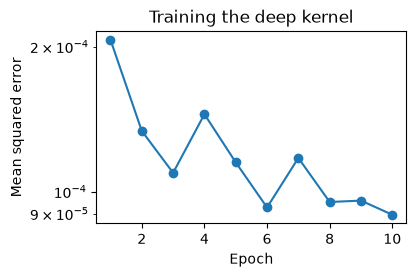

In [9]:
plt.figure(figsize=(4, 2.5))
plt.semilogy(range(1, len(history) + 1), history, 'o-')
plt.xlabel('Epoch')
plt.ylabel('Mean squared error')
plt.title('Training the deep kernel')
plt.show()

The trained U-Net makes the kernel for the whole image, in the same form as `construct_kernel`'s, and KEM uses it the
same way:

In [10]:
t0 = time.time()
deep_weights, deep_indices = construct_deep_kernel(model, pet_prior, chunk_size=512, device=pytomography.device,
                                                   **deep_params)
deep_kem = KEM(PoissonLogLikelihood(KEMSystemMatrix(system_matrix, ExternalKEMTransform(deep_weights, deep_indices)),
                                    projections))
recon_deep_kem = deep_kem(n_iters=50, n_subsets=1)
print(f"deep kernel and KEM, 50 iterations: {time.time() - t0:.0f} s")
del deep_kem, deep_weights, deep_indices

deep kernel and KEM, 50 iterations: 44 s


## 5. The three reconstructions

The PET prior on top, then the three SPECT reconstructions after 50 iterations each, on one scale. Both kernels
remove most of MLEM's noise. The kernel from the PET intensities also blurs the organs' edges a little; the
deep-learned kernel keeps them as sharp as in the PET image.

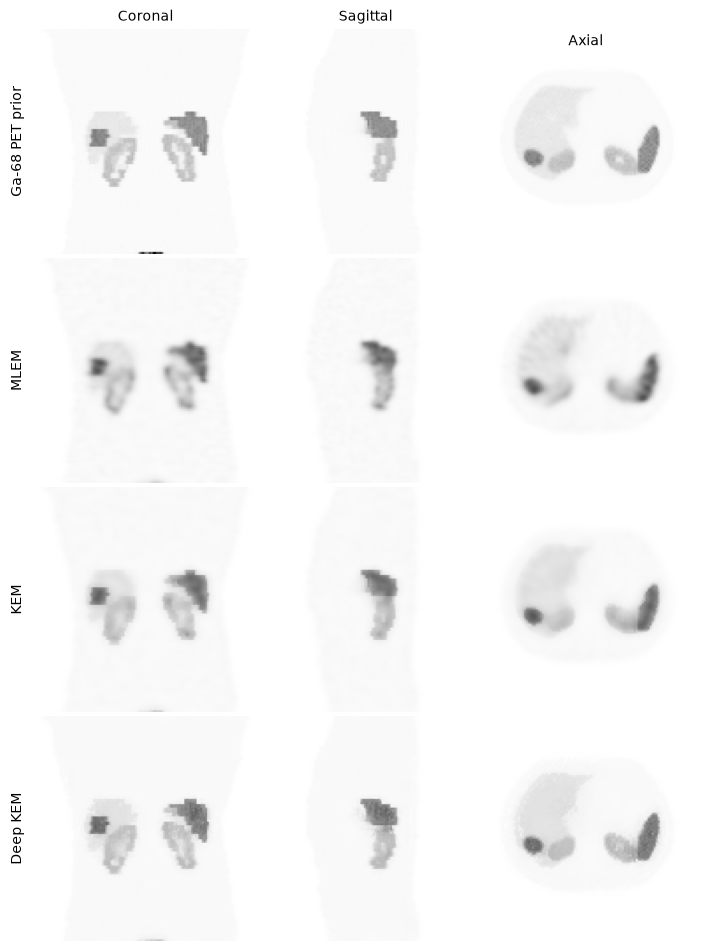

In [11]:
images = [(pet_prior, 'Ga-68 PET prior'), (recon_mlem.cpu().numpy(), 'MLEM'), (recon_kem.cpu().numpy(), 'KEM'),
          (recon_deep_kem.cpu().numpy(), 'Deep KEM')]
vmax = max(float(image.max()) for image, _ in images[1:])
x, y, z = 89, 60, 65  # the slices shown
body = slice(10, 98)  # the body's extent in y
fig, axes = plt.subplots(len(images), 3, figsize=(7.4, 9.6), gridspec_kw=dict(width_ratios=[128, 88, 128]))
for row, (image, name) in enumerate(images):
    top = image.max() if row == 0 else vmax
    # head up in the coronal and sagittal views, the patient's right on the left in the coronal and axial ones
    views = [(image[:, y, :].T, 'Coronal', 'lower'), (image[x, body, :].T, 'Sagittal', 'lower'),
             (image[:, body, z].T, 'Axial', 'upper')]
    for col, (view, plane, origin) in enumerate(views):
        ax = axes[row, col]
        ax.imshow(view, cmap='Greys', origin=origin, vmin=0, vmax=top)
        ax.axis('off')
        if row == 0:
            ax.set_title(plane, fontsize=10)
        if col == 0:
            ax.text(-0.04, 0.5, name, transform=ax.transAxes, rotation=90, va='center', ha='right', fontsize=10)
plt.subplots_adjust(left=0.05, right=0.99, bottom=0.01, top=0.96, wspace=0.02, hspace=0.02)
plt.show()

In [12]:
np.savez_compressed(OUTPUT / 'kem_reconstructions.npz', mlem=recon_mlem.cpu().numpy(), kem=recon_kem.cpu().numpy(),
                    deep_kem=recon_deep_kem.cpu().numpy())
print(f"saved to {OUTPUT / 'kem_reconstructions.npz'}")

saved to C:\v4runs\laptop\outputs-r2\SPECT\Lu177-DOTATATE-Zubal\kem_reconstructions.npz


In [13]:

import json, platform, torch, pytomography
def _peak_ram_gb():
    try:
        import psutil
        m = psutil.Process().memory_info()
        if hasattr(m, "peak_pagefile"):  # Windows: peak committed memory
            return round(m.peak_pagefile / 1e9, 1)
    except ImportError:
        pass
    import resource  # ru_maxrss is in kB on Linux, bytes on macOS
    return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e9 if platform.system() == "Darwin" else 1e6), 1)
_info = dict(pytomography=getattr(pytomography, "__version__", "?"), source=pytomography.__file__,
             torch=torch.__version__, python=platform.python_version(),
             gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
             peak_gpu_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else 0.0,
             peak_ram_gb=_peak_ram_gb())
print("__PYTOMOGRAPHY_RUN__" + json.dumps(_info))


__PYTOMOGRAPHY_RUN__{"pytomography": "4.0.0rc1", "source": "C:\\Users\\lukep\\miniforge3\\envs\\pytomo-rc1\\Lib\\site-packages\\pytomography\\__init__.py", "torch": "2.14.1+cu130", "python": "3.12.16", "gpu": "NVIDIA GeForce RTX 5060 Laptop GPU", "peak_gpu_gb": 1.44, "peak_ram_gb": 9.1}
